# 논문 기반 추가 개선: 무엇이 좋아졌고, 무엇이 실패했나?

Process-only Isolation Forest / MiniBatch K-means, 각각 전체·Adapter·앙상블 6개 경로를 비교한다.
기존 v4와 원본 평가 CSV/라벨은 보존했다. v5/v6/v7은 각각 새 탐색·확인 사례를 사용한 후 동결했다.
이 노트북은 **이미 계산된 결과를 읽을 뿐 재학습·threshold 재선택을 하지 않는다.**

읽는 순서: 개선 수치 → 평가 분모 → 논문·실제 적용 → 실패 실험 → 확인 집단 → 시나리오 → Adapter → 점수 분포 → 3번째 모델.
평가셋은 이전에도 살펴본 합성 데이터다. **새 블라인드 평가나 실제 장애 탐지 성능이라고 주장하지 않는다.**

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
HERE=Path.cwd()
ROOT=next(p for p in (HERE,*HERE.parents) if (p/'code/model_research_v5/report.py').exists())
sys.path.insert(0,str(ROOT/'code'))
from model_research_v5 import report
from model_research_v5.models import METHODS
report.setup()
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 90)
s=report.read('v7')
audit=json.loads((ROOT/'reports/model_research_v7/audit.json').read_text(encoding='utf-8'))

## 1. 개선 전후: F1와 정상 오탐을 함께 읽기

F1 상승만으로 개선을 확정하지 않는다. 이상을 많이 찍으면 Recall이 오르지만 정상 오탐도 늘 수 있다.
v5는 자기 과거 대비 피처, v6는 트래픽/지연 채널 분리, v7은 정상 재생 분포를 맞춘 실험이다.
**버전 번호가 높다고 성능이 더 좋다는 뜻은 아니다.** 최종 파일을 운영 모델로 자동 교체하지 않았다.

,모델,v4 F1 (%),v7 F1 (%),F1 변화 (%p),v4 오탐 (%),v7 오탐 (%),오탐 변화 (%p)
0,IF 전체,23.28,25.95,2.66,5.70,1.37,-4.32
1,IF Adapter,22.43,21.33,-1.10,4.52,1.38,-3.14
2,IF 앙상블,23.55,24.14,0.59,4.22,1.15,-3.07
3,K-means 전체,35.38,21.89,-13.49,2.80,1.10,-1.70
4,K-means Adapter,31.86,16.16,-15.69,4.27,2.68,-1.60
5,K-means 앙상블,35.92,17.09,-18.83,5.15,2.45,-2.71


,모델,v4 F1 (%),v6 F1 (%),F1 변화 (%p),v4 오탐 (%),v6 오탐 (%),오탐 변화 (%p)
0,IF 전체,23.28,23.97,0.69,5.70,1.36,-4.33
1,IF Adapter,22.43,21.70,-0.72,4.52,1.38,-3.14
2,IF 앙상블,23.55,24.37,0.83,4.22,1.78,-2.44
3,K-means 전체,35.38,30.34,-5.04,2.80,55.29,52.49
4,K-means Adapter,31.86,27.60,-4.25,4.27,43.23,38.95
5,K-means 앙상블,35.92,30.66,-5.25,5.15,54.74,49.59


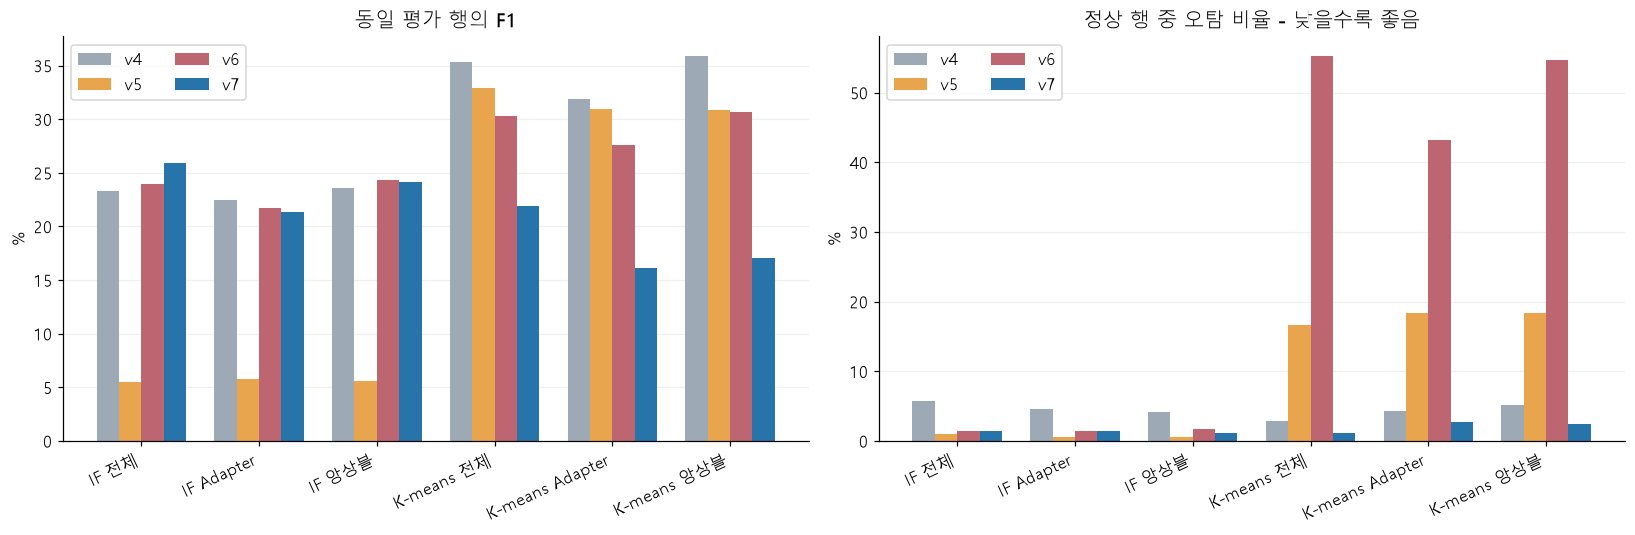

In [2]:
display(report.changes('v7'))
display(report.changes('v6'))
report.compare_bars(); plt.show()

### 수치 해석

왼쪽은 F1(클수록 좋음), 오른쪽은 정상 행 오탐(작을수록 좋음)이다.
각 버전은 피처·학습 참고 집단·threshold·가중치가 달라 **알고리즘만 바꾼 통제 실험이 아니다.**
K-means 개선 시도가 기존 v4보다 나빠졌다면 그 사실을 유지하고, 기존 K-means를 보존하는 것이 맞다.
이 노트북의 v7은 결과를 공개하기 위한 연구 후보이지 최종 우승 모델이라는 선언이 아니다.

### 이번 실험의 결론부터

- **IF 전체:** F1 23.28%→25.95%, Precision 37.20%→69.81%, 정상 오탐 5.70%→1.37%.
  Recall은 16.94%→15.93%로 조금 감소했다. 더 많이 잡은 개선이 아니라 **경보를 더 정확하게 만든 개선**이다.
- IF 앙상블: F1 23.55%→24.14%, 오탐 4.22%→1.15%. Adapter 단독은 F1이 내려가서 항상 우월하지 않다.
- **K-means 종합 개선은 실패:** 전체 F1 35.38%→21.89%, 앙상블 35.92%→17.09%.
  오탐을 줄였지만 이상도 많이 놓쳤다. 종합 비교의 K-means 기준은 기존 v4를 유지하는 것이 타당하다.
- v7 K-means 전체는 컬럼 관계·개별 지연의 F1이 올랐지만 그 시나리오의 오탐도 늘었다. 특화 연구 후보로만 남긴다.
- 다음 모델은 USAD 계열 시계열 Autoencoder를 제안한다. 아직 성능 검증 전이며 향상을 보장하지 않는다.

운영 v1 파일이나 backend 기본 모델은 변경하지 않았다. v7 joblib에는 실패한 K-means 후보도 들어 있으므로
파일 전체를 '모든 모델이 개선된 최종 버전'이라고 보고 자동 배포하면 안 된다.

## 2. 최종 평가의 6개 모델과 분모

기본 6종은 각각 이상 사례 5,000개 + 짝지은 정상 사례 5,000개, 혼합 Hard는 1,000+1,000개다.
**62,000개 사례를 1분 의사결정 행으로 평가**했기 때문에 62,000행의 분류 성능이 아니다.
한 행을 맞혔다고 사건 전체를 정답으로 바꾸는 point adjustment는 없다.
STATUS는 모두 S이며 원본에 대한 동결 하드 룰 점검은 모두 통과한 벤치마크다.

총 **2,167,766개 의사결정**: 정상 1,807,717, 이상 360,049. 모두 정상으로 찍어도 Accuracy **83.39%**이므로 Accuracy만 보지 말 것.

,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,84.89,69.81,15.93,25.95,1.37
1,IF Adapter,84.36,64.84,12.76,21.33,1.38
2,IF 앙상블,84.84,71.53,14.52,24.14,1.15
3,K-means 전체,84.63,70.20,12.97,21.89,1.10
4,K-means Adapter,82.82,42.61,9.97,16.16,2.68
5,K-means 앙상블,83.09,46.06,10.49,17.09,2.45


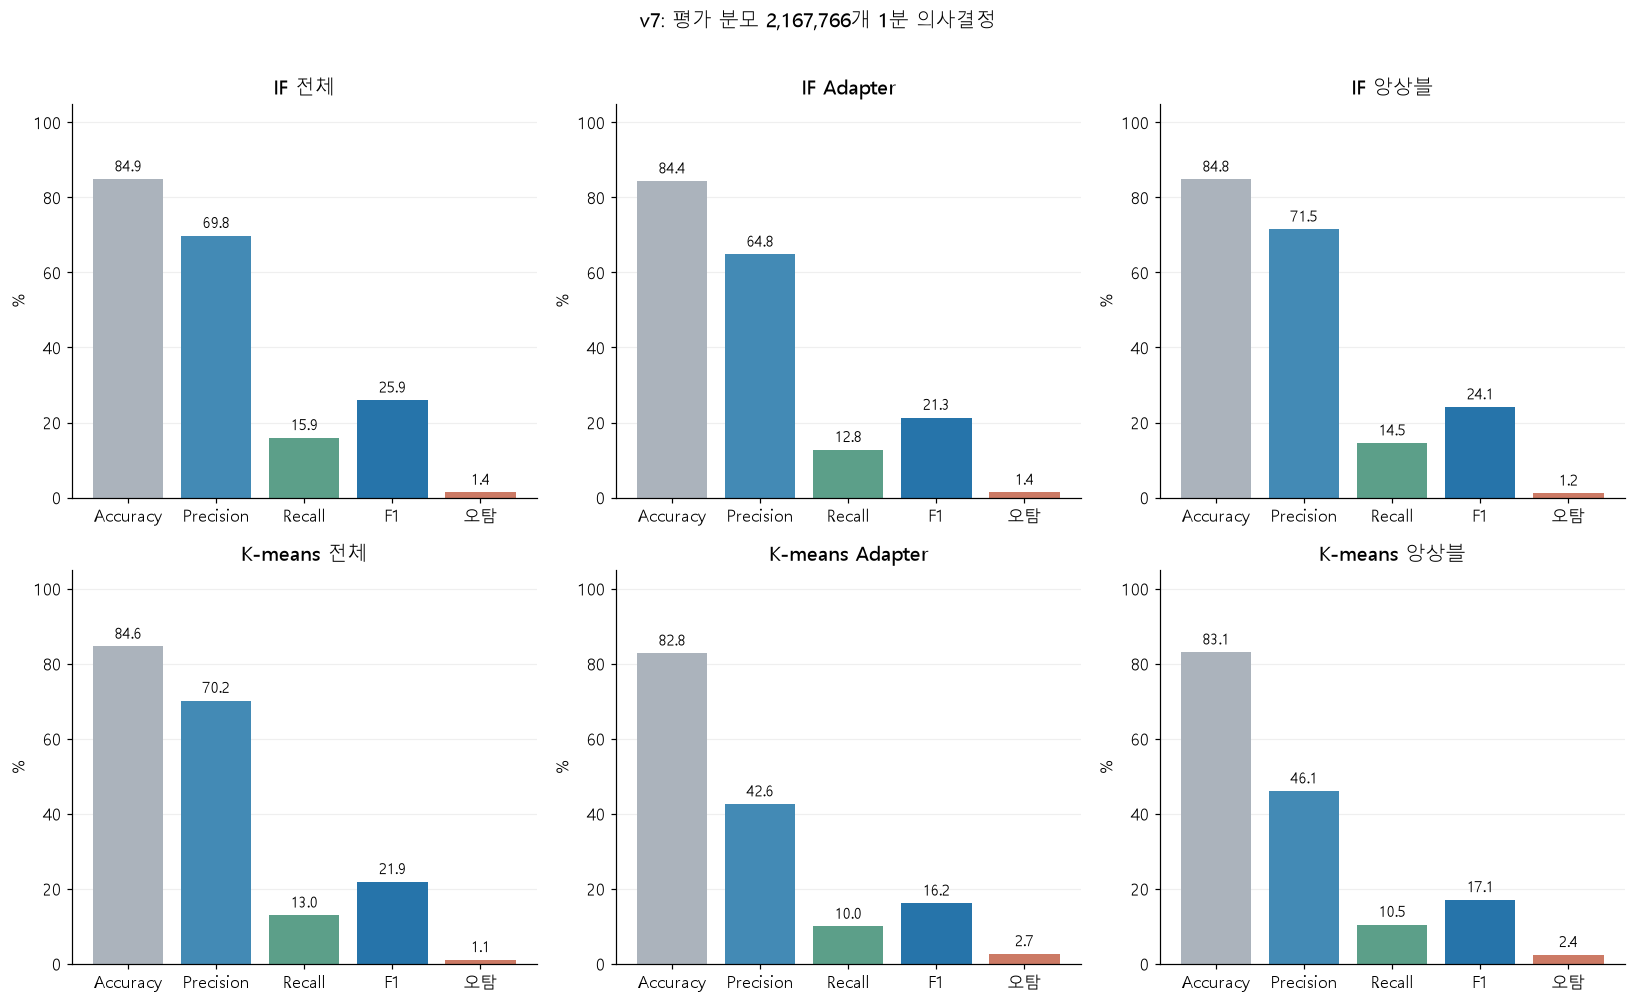

In [3]:
first=s['pooled'][0]
display(Markdown(f"총 **{first['n']:,}개 의사결정**: 정상 {first['normal']:,}, 이상 {first['anomaly']:,}. "
                 f"모두 정상으로 찍어도 Accuracy **{first['always_normal_accuracy']:.2%}**이므로 Accuracy만 보지 말 것."))
display(report.metrics(s['pooled']))
report.six_bars(); plt.show()

## 3. 참고 논문과 실제 적용 범위

| 논문 | 참고한 핵심 | 이번 적용 상태 |
|---|---|---|
| [Extended Isolation Forest — Hariri 등](https://arxiv.org/abs/1811.02141) | 축 정렬 분할의 편향, 무작위 회전/초평면 | v5/v6에 4개 회전 블록 후보 구현·비교. **full EIF 재현 아님**, v7은 일반 IF |
| [Neural Contextual Anomaly Detection — Carmona 등, 2021](https://arxiv.org/abs/2107.07702) | 과거 맥락과 현재 의심 구간 비교 | 직전 값 대비 지연·추세 피처에 아이디어 적용. **TCN/COE/Mixup/NCAD 학습 재현 아님** |
| [LOF — Breunig 등, SIGMOD 2000](https://doi.org/10.1145/335191.335388) | 주변 정상 이웃과 상대적 밀도 비교 | novelty LOF 이웃 30/75 비교, 검증 전용 후보로 실제 실행 |
| [ECOD — Li 등, 2022](https://arxiv.org/abs/2201.00382) | 경험적 CDF의 양쪽 꼬리 | 문헌 검토만. v6 채널 꼬리 보정은 **ECOD 알고리즘이 아님** |
| [Anomaly Detection in Streams with EVT — Siffer 등, KDD 2017](https://www.amossys.fr/wp-content/uploads/anomaly-detection-with-evt-1.pdf) | 정상 꼬리와 스트림 threshold | 문헌 검토만. 경험적 분위수는 **GPD/EVT/SPOT 구현 아님** |
| [Towards a Rigorous Evaluation — Kim 등, ICLR 2022](https://arxiv.org/abs/2109.05257) | point adjustment의 과대평가 문제 | PA 없이 분 단위 F1, 사건 Recall을 별도로 계산 |
| [Exathlon — Jacob 등, VLDB 2021](https://arxiv.org/abs/2010.05073) | 탐지·사건 범위·설명 평가를 구분 | 시나리오/사건 지표 분리의 참고. **Exathlon 데이터나 모델 재현 아님** |
| [USAD — Audibert 등, KDD 2020](https://www.kdd.org/kdd2020/accepted-papers/view/usad-unsupervised-anomaly-detection-on-multivariate-time-series.html) | 다변량 시간창 재구성 | 3번째 모델 제안, **미구현·미평가** |
| [TranAD — Tuli 등, VLDB 2022](https://arxiv.org/abs/2201.07284) | Attention 기반 시계열 탐지 | 대안 검토만, 미구현·미평가 |

논문의 공개 F1을 우리 결과와 직접 비교하지 않는다. 데이터·threshold 선택·PA 여부가 다르다.
특히 NCAD 논문의 해당 실험 프로토콜에는 PA와 test 최적 threshold가 있는데, 그것을 가져오지 않았다.

## 4. 어떻게 바꿨나: 정상 분포·인과적 피처·보정

1. v5: 현재 분 완료 로그를 직전 5분과 비교. `shift(1)` 후 rolling으로 자기 자신을 참고값에 넣지 않음.
   지연 변화, P95 변화, 추세, 꼬리 폭, EWMA, 누적 양의 변화 후보를 만들었다.
2. v5: 같은 정상 로그를 6/15/90분 reset view로 재사용. **독립 원본 데이터가 3배 늘어난 것이 아님.**
3. v6: 트래픽 4피처와 지연 6피처를 각각 모델링. 정상 calibration의 경험적 꼬리 순위로 점수를 맞춘 후 최대값을 보정.
   지연은 직전 5분에 완료 관측 2개 이상이 있어야 평가 가능. 미평가 행도 최종 분모에 남겼다.
4. v7: 학습 원본에서 짧은 단일 실행, 두 실행, 36/60분 연속 실행을 재생하고 지원 집단의 P05~P75 정상 소요시간을 샘플링.
   **평가 CSV나 정답을 쉽게 바꾸지 않고, 정상 학습/보정 데이터의 생성 방식을 바꿨다.**

v7의 정상 재생은 원본 train/calibration/threshold 각각의 템플릿만 사용한다. 검증·평가용 예약 템플릿은 제외했다.
하지만 원래 평가 생성기를 알고 맞춘 것이므로 **합성 도메인 적응**에 해당한다. 실제 정상의 P75 이후 꼬리를 제외해도 안전하다는 의미가 아니다.

,partition,episodes,windows,source_templates,central_sampling
0,train,360,9593,4448,True
1,calibration,432,11558,1952,True
2,threshold,384,10358,1917,True


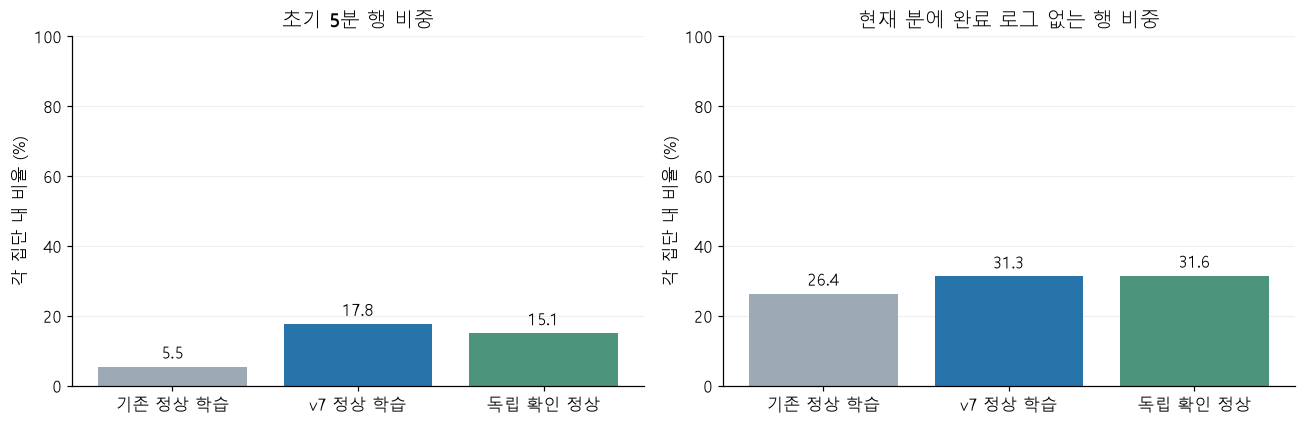

In [4]:
display(pd.DataFrame(report.read('v7','preparation')['normal_references']))
report.source_shift_bars(); plt.show()

### 위 그림의 의미

짧은 사례는 초기 구간·완료 로그 없는 행 비율이 높다. 90분 재생만으로 기준을 잡으면 이 정상 상태를 이상으로 오해할 수 있다.
두 비율이 가까워졌다고 모든 피처 분포가 같아졌다는 의미는 아니다.
소요시간·업무 구성·불연속 수집 같은 추가 차이는 여전히 남는다.

## 5. 하이퍼파라미터와 threshold

v7 IF는 128 trees, max_samples 256/1024 등을 비교. v5 회전 후보는 128 trees를 4개 블록에 나눴다.
v6은 채널당 128 trees이므로 두 채널을 합치면 전체/각 전문가당 256 trees였다.
K-means는 K=6/12, 군집별 퍼짐 보정 후보, batch_size=2048, n_init=5, max_iter=100.
스케일러의 중앙값·P10~P90 범위는 정상 train에서만 학습한다.

탐색: 4개 피처 view, IF 2설정/K-means 3설정, 초기/steady 보정 여부 2개 × 분위수 4개 × 가중치 3개.
IF 192개, K-means 288개 운용점을 비교했다. 목적은 6시나리오 F1을 같은 비중으로 평균한 뒤 3경로를 평균.
**각 시나리오·경로 정상 오탐 ≤5%**가 제약이다. 없으면 최소 최악 오탐 후보를 `within_budget=False`로 공개한다.
v4의 합산 오탐 제약보다 엄격하므로 동일 튜닝 조건의 반복 실험이라고 주장하지 않는다.

`contamination='auto'`의 기본 판정을 쓰는 것이 아니다. 정상 threshold 집단의 선택 분위수로 판정선을 만든다.
전체·Adapter 점수를 정상 기준으로 정규화하고, 앙상블 가중합의 threshold도 따로 정상 데이터에서 보정한다.

In [5]:
display(report.selected_settings())
display(pd.DataFrame(s['thresholds']).round(5))

,알고리즘,피처 view,max_samples,K,회전 블록,군집 모양 보정,정상 기준 quantile,전체 모델 가중치,초기/정상 구간별 threshold,탐색 오탐 제약 충족
0,if,temporal,256.0,NaN,1.0,None,0.990,0.75,True,True
1,kmeans,relational,NaN,6.0,NaN,False,0.999,0.25,False,False


,algorithm,settings,route,phase,quantile,global_weight,phase_aware,normalized_threshold,ensemble_threshold,normalizer_center,normalizer_spread,raw_threshold
0,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",GLOBAL,startup,0.990,0.75,True,1.17067,1.17067,0.53887,0.08085,0.63352
1,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",GLOBAL,steady,0.990,0.75,True,1.68537,1.68537,0.51305,0.05582,0.60712
2,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",DB.READER,startup,0.990,0.75,True,1.07347,1.03781,0.61348,0.06320,0.68133
3,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",DB.READER,steady,0.990,0.75,True,1.42802,1.68313,0.60775,0.03855,0.66281
4,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",DB.WRITER,startup,0.990,0.75,True,1.68067,1.00161,0.57636,0.03858,0.64120
5,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",DB.WRITER,steady,0.990,0.75,True,1.44647,1.51640,0.55673,0.05050,0.62978
6,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",FILE.READER,startup,0.990,0.75,True,1.41357,0.92507,0.61315,0.04893,0.68231
7,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",FILE.READER,steady,0.990,0.75,True,1.76354,1.58989,0.61017,0.03788,0.67698
8,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",FILE.WRITER,startup,0.990,0.75,True,0.91681,0.79351,0.63397,0.04554,0.67573
9,if,"{'algorithm': 'if', 'samples': 256, 'rotations': 1, 'k': 6, 'shape_distance': False, '...",FILE.WRITER,steady,0.990,0.75,True,1.23903,1.71334,0.62682,0.03944,0.67569


## 6. 새 확인 사례에서 정말 좋아졌나?

각 버전은 새 1,440개 주입 사례 + 정상 쌍을 720개 탐색/720개 확인으로 나눴다.
확인 집단은 설정 동결 후 1회 평가했고 재선택에 쓰지 않았다. Hard는 탐색에 사용하지 않았다.
정상 fit만 비지도이며, 시나리오 라벨을 사용한 설정 선택까지 포함하면 **라벨 검증을 활용한 튜닝**이다.
같은 원본 예약 풀과 생성기를 공유하므로 실제 미래 데이터의 독립 검증은 아니다.

In [6]:
display(report.validation_table())
display(Markdown('새 확인 집단의 결과를 보고 threshold를 다시 맞추지 않았음.'))

,설정,모델,확인 F1 (%),확인 정상 오탐 (%)
0,baseline_v4,IF 전체,24.69,5.48
1,baseline_v4,IF Adapter,25.14,5.73
2,baseline_v4,IF 앙상블,26.29,5.11
3,baseline_v4,K-means 전체,42.72,4.81
4,baseline_v4,K-means Adapter,35.31,10.87
5,baseline_v4,K-means 앙상블,41.72,10.39
6,matched_normal_defaults,IF 전체,4.17,1.60
7,matched_normal_defaults,IF Adapter,4.85,1.60
8,matched_normal_defaults,IF 앙상블,3.57,0.76
9,matched_normal_defaults,K-means 전체,31.91,4.32


새 확인 집단의 결과를 보고 threshold를 다시 맞추지 않았음.

## 7. 어떤 이상에 강하고 약한가?

행이 많은 폭주·중단 시나리오가 합산 점수를 좌우한다. 개별 지연·관계 이상은 별도로 봐야 한다.
첫 번째 표는 전체 모델, 아래 그래프는 앙상블을 비교한다.
처음 보는 업무라도 기존 Adapter라면 전문가를 쓸 수 있지만, 정상 분포가 다르면 전문가도 오탐이 날 수 있다.

,시나리오,모델,F1 (%),Recall (%),정상 오탐 (%)
0,개별 지연,IF 전체,0.00,0.00,5.24
1,개별 지연,IF 앙상블,0.00,0.00,3.34
2,개별 지연,K-means 전체,17.63,10.90,1.17
3,개별 지연,K-means 앙상블,16.80,14.66,5.48
4,집단 지연,IF 전체,2.11,1.12,0.80
5,집단 지연,IF 앙상블,0.99,0.52,0.74
6,집단 지연,K-means 전체,33.20,22.41,2.25
7,집단 지연,K-means 앙상블,25.72,19.32,5.51
8,컬럼 관계,IF 전체,0.00,0.00,5.53
9,컬럼 관계,IF 앙상블,0.00,0.00,2.83


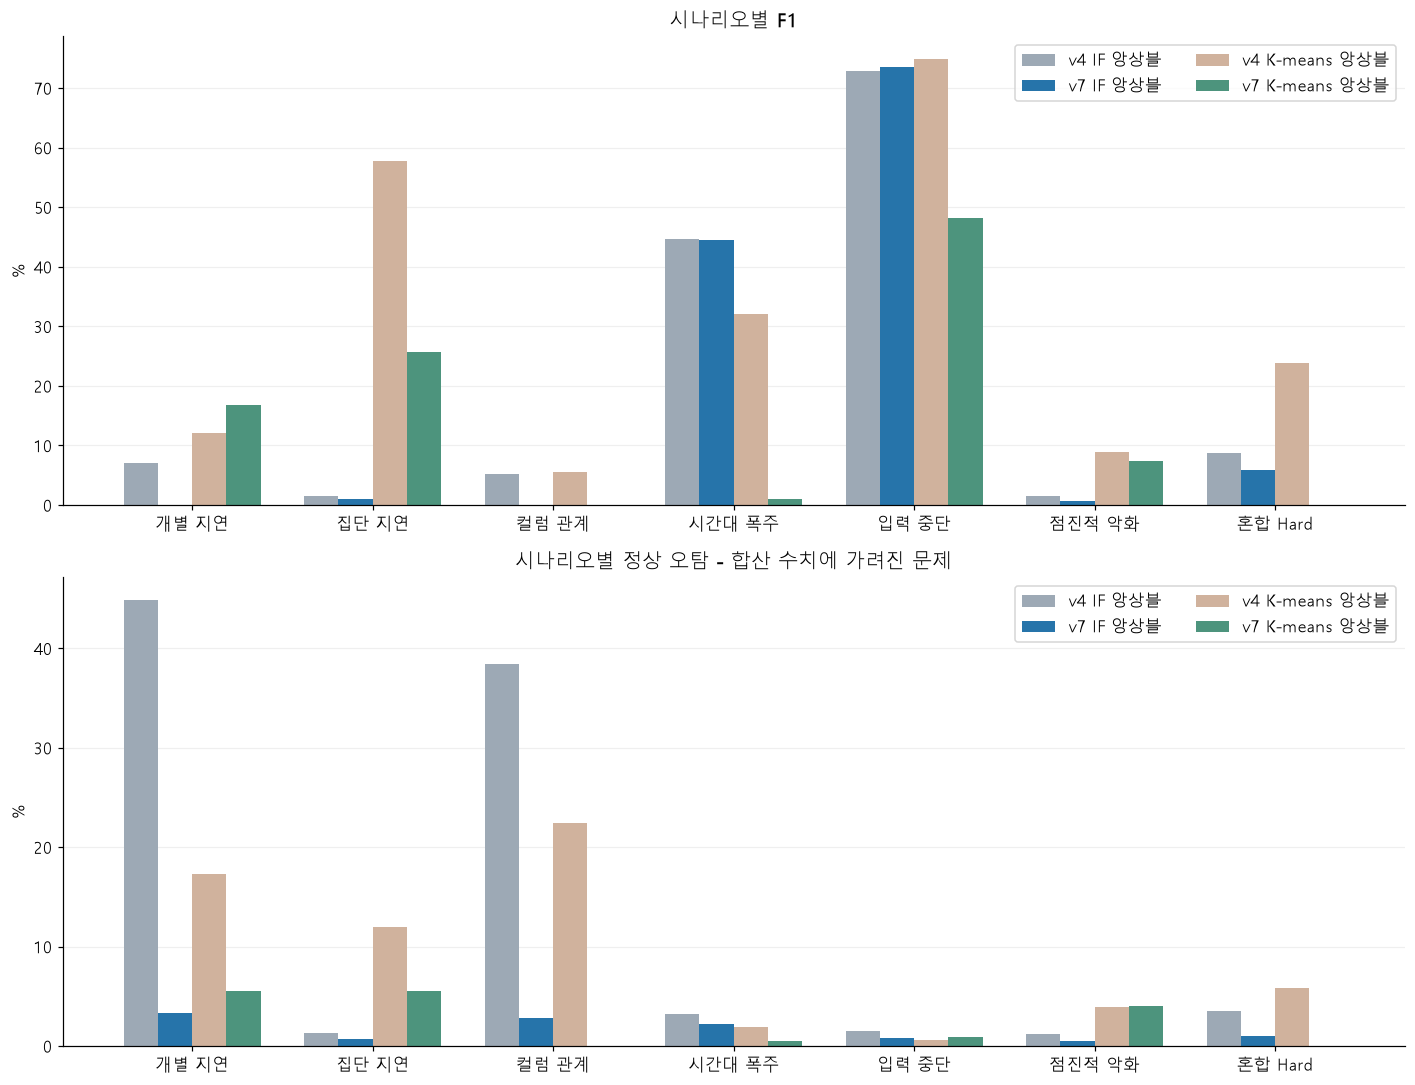

,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,85.24,32.62,17.55,21.11,2.55
1,IF Adapter,85.57,29.86,13.95,18.23,1.71
2,IF 앙상블,85.78,30.45,16.12,19.95,1.74
3,K-means 전체,86.48,48.80,16.22,23.13,1.28
4,K-means Adapter,84.40,28.08,11.45,15.63,2.97
5,K-means 앙상블,84.68,29.66,12.11,16.51,2.74


In [7]:
rows=[]
for d in s['datasets']:
    for i in (0,2,3,5):
        r=d['metrics'][i]
        rows.append({'시나리오':report.SCENARIOS[d['dataset']], '모델':report.LABELS[i],
                     'F1 (%)':r['f1']*100, 'Recall (%)':r['recall']*100, '정상 오탐 (%)':r['normal_false_positive_rate']*100})
display(pd.DataFrame(rows).round(2))
report.scenario_bars(); plt.show()
display(report.metrics(s['basic_macro']))

## 8. Adapter 모델의 실제 효과와 fallback

Adapter는 모델 피처가 아니라 경로 선택값이고 Process ID는 과거 참고값/스트림 구분에 사용한다.
Transaction 테이블은 모델 입력에 쓰지 않는다. transactionId는 Process 행에서 실행 수 중복 집계를 피할 때만 사용한다.
각 전문가에 train 500창, calibration/threshold 100창과 각 원본 집단의 서로 다른 업무 20개 이상을 요구한다.
재생 행이 많아져도 원본 업무 수를 부풀려 전문가를 만들지 않는다.

지원되지 않는 Adapter는 전체 모델 점수·threshold로 정확히 fallback한다.
전체 평가표의 `Adapter` 경로는 이런 fallback 행도 포함하므로 **전문가가 있는 행만 따로 봐야 효과를 알 수 있다.**

,adapter,train,calibration,threshold,source_workflows,expert_available,reason
0,DATA.DECRYPTOR,0,607,0,{'calibration': 1},False,train<500; threshold<100; train_source_workflows<20; calibration_source_workflows<20; ...
1,DATA.ENCRYPTOR,0,626,0,{'calibration': 1},False,train<500; threshold<100; train_source_workflows<20; calibration_source_workflows<20; ...
2,DATA.MAPPER,628,656,650,"{'train': 2, 'calibration': 4, 'threshold': 6}",False,train_source_workflows<20; calibration_source_workflows<20; threshold_source_workflows<20
3,DATA.TRANSFORMER,657,654,646,"{'train': 5, 'calibration': 8, 'threshold': 19}",False,train_source_workflows<20; calibration_source_workflows<20; threshold_source_workflows<20
4,DB.DELETER,627,0,625,"{'train': 1, 'threshold': 1}",False,calibration<100; train_source_workflows<20; calibration_source_workflows<20; threshold...
5,DB.EXECUTOR,631,654,644,"{'train': 1, 'calibration': 764, 'threshold': 735}",False,train_source_workflows<20
6,DB.READER,656,649,652,"{'train': 1536, 'calibration': 469, 'threshold': 475}",True,supported
7,DB.UPDATER,654,655,651,"{'train': 7, 'calibration': 13, 'threshold': 12}",False,train_source_workflows<20; calibration_source_workflows<20; threshold_source_workflows<20
8,DB.WRITER,651,653,654,"{'train': 1537, 'calibration': 461, 'threshold': 464}",True,supported
9,FILE.EXECUTOR,0,652,653,"{'calibration': 3, 'threshold': 4}",False,train<500; train_source_workflows<20; calibration_source_workflows<20; threshold_sourc...


,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,81.42,56.73,7.84,13.78,1.40
1,IF Adapter,80.37,27.95,2.34,4.32,1.41
2,IF 앙상블,81.32,57.06,5.38,9.84,0.95
3,K-means 전체,81.86,59.67,12.98,21.32,2.05
4,K-means Adapter,78.28,25.69,7.79,11.95,5.26
5,K-means 앙상블,78.82,29.72,8.69,13.44,4.80


전체 2,167,766개 중 **1,071,698개**는 전문가 미지원으로 전체 모델과 동일 판정.

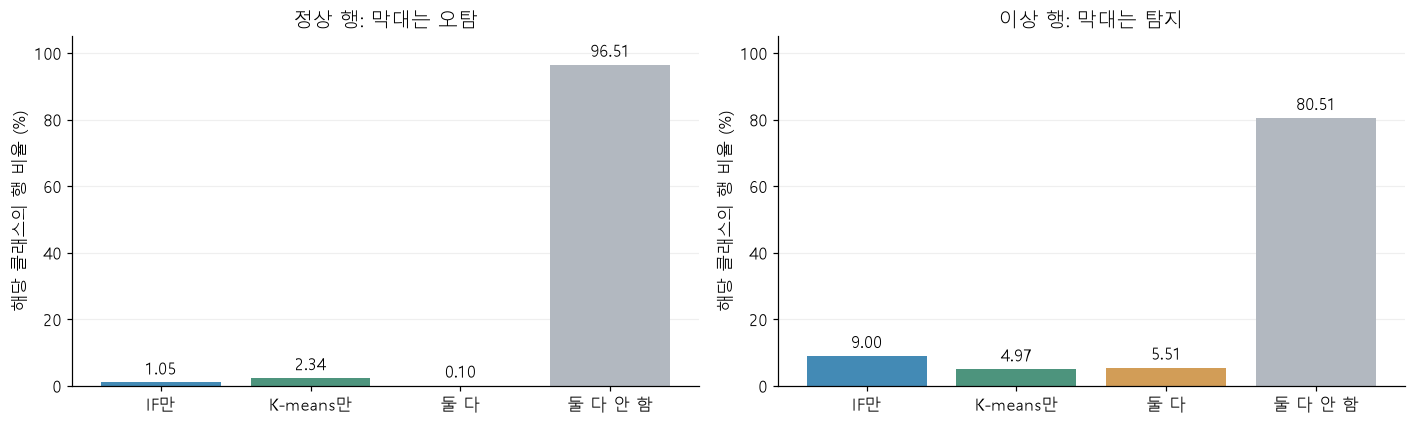

In [8]:
display(pd.DataFrame(s['support']))
display(report.metrics(s['supported_only']))
v=audit['verification']['v7']
display(Markdown(f"전체 {v['decisions']:,}개 중 **{v['fallback_decisions']:,}개**는 전문가 미지원으로 전체 모델과 동일 판정."))
report.agreement_bars(audit); plt.show()

### 모델별 역할을 해석하는 방법

IF: 정상 자료에서 드물고 쉽게 분리되는 조합을 찾는다. 거리 중심 모델과 다른 탐지 근거다.
K-means: 여러 정상 패턴의 중심과 얼마나 멀어졌는지 본다. 군집별 정상 반경을 나눠 넓은 집단의 불필요한 경보를 줄인다.
`IF만/K-means만/둘 다` 비율은 **이번 설정의 상보성**이지 두 알고리즘의 보편적 우열이 아니다.
알고리즘뿐 아니라 피처와 threshold도 다르기 때문이다. 단순 OR 결합은 정상 오탐도 함께 늘릴 수 있다.

## 9. 정상·이상 점수 분포와 threshold를 어떻게 읽나?

일반 막대 히스토그램이다. X축은 `정규화 점수 - 해당 경로 threshold`(margin), 점선은 0.
점선 오른쪽이면 이상 판정, 정상 막대가 오른쪽에 있으면 오탐, 이상 막대가 왼쪽이면 미탐이다.
초기/steady·Adapter마다 threshold가 달라 원시 점수를 섞지 않고 **threshold를 뺀 margin**으로 보여준다.
정규분포가 되는 것이 목표가 아니다. 분포 겹침과 실제 정상 오탐이 중요하다.
그림은 파일당 최대 12,000개를 샘플링했고 양끝 0.5%를 끝 bin에 합쳤다. 성능표는 전체 행이다.

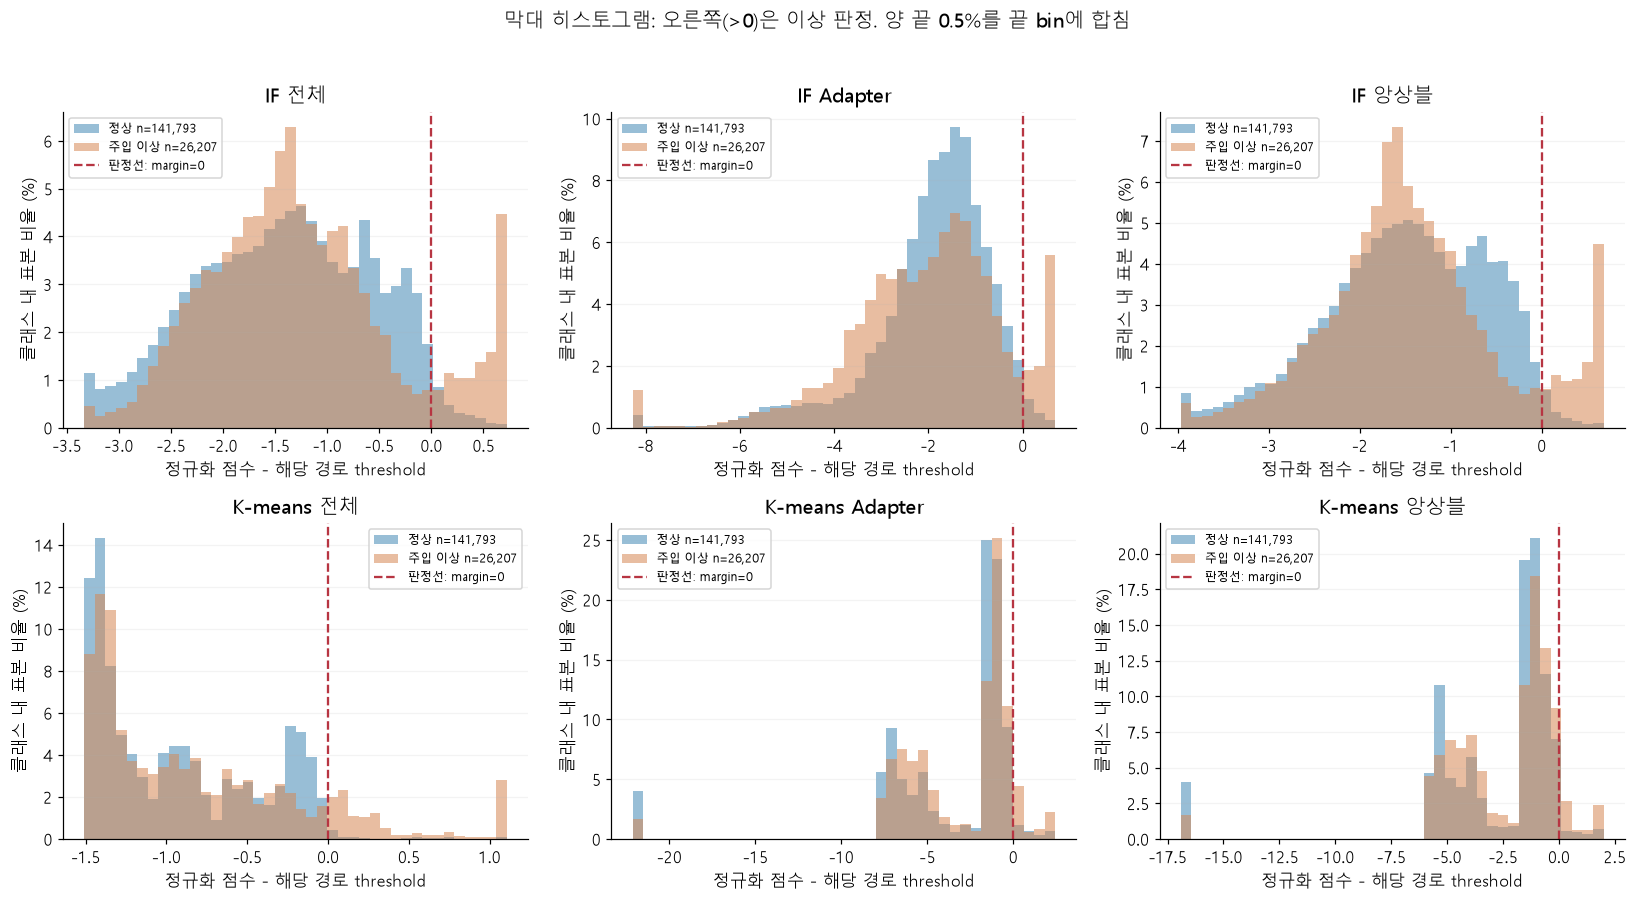

,구간,모델,행 수,F1 (%),정상 오탐 (%)
0,startup,IF 전체,309990,0.00,1.05
1,startup,IF Adapter,309990,0.00,1.23
2,startup,IF 앙상블,309990,0.00,1.22
3,startup,K-means 전체,309990,19.78,0.89
4,startup,K-means Adapter,309990,6.39,2.55
5,startup,K-means 앙상블,309990,6.54,2.29
6,steady,IF 전체,1857776,27.05,1.44
7,steady,IF Adapter,1857776,22.29,1.41
8,steady,IF 앙상블,1857776,25.22,1.14
9,steady,K-means 전체,1857776,21.99,1.14


In [9]:
report.margin_histograms(); plt.show()
rows=[]
for phase,records in audit['verification']['v7']['phase_metrics'].items():
    for i,r in enumerate(records):
        rows.append({'구간':phase,'모델':report.LABELS[i],'행 수':r['n'],'F1 (%)':r['f1']*100,'정상 오탐 (%)':r['normal_false_positive_rate']*100})
display(pd.DataFrame(rows).round(2))

## 10. 사건 단위 지표와 어려운 Hard

분 단위 F1와 사건 Recall은 다르다. 사건에 한 번이라도 경보가 있었는지, 정상 사례에 한 번이라도 경보가 났는지를 별도로 읽는다.
이 지표로 분 단위 라벨을 바꾸지 않는다. 혼합 Hard에서 6종 모두를 찾은 사례 비율도 분리한다.

In [10]:
hard=next(d for d in s['datasets'] if d['dataset']=='mixed_hard')
ev=pd.DataFrame(hard['events']['per_type'])
ev['scenario']=ev.scenario.map(report.SCENARIOS)
ev['method']=ev.method.map(dict(zip(METHODS,report.LABELS)))
display(ev)
display(pd.DataFrame({'모델':report.LABELS,
                      '정상 Hard 사례 경보 (%)':[hard['events']['normal_case_false_alarm_rate'][m]*100 for m in METHODS],
                      '6종 모두 탐지한 Hard 사례 (%)':[hard['events']['all_six_recall'][m]*100 for m in METHODS]}).round(2))

,scenario,method,events,detected,event_recall,median_delay_seconds
0,개별 지연,IF 전체,1000,4,0.004,120.0
1,개별 지연,IF Adapter,1000,32,0.032,60.0
2,개별 지연,IF 앙상블,1000,2,0.002,120.0
3,개별 지연,K-means 전체,1000,104,0.104,120.0
4,개별 지연,K-means Adapter,1000,0,0.000,NaN
5,개별 지연,K-means 앙상블,1000,2,0.002,120.0
6,집단 지연,IF 전체,1000,54,0.054,180.0
7,집단 지연,IF Adapter,1000,43,0.043,120.0
8,집단 지연,IF 앙상블,1000,31,0.031,180.0
9,집단 지연,K-means 전체,1000,511,0.511,240.0


,모델,정상 Hard 사례 경보 (%),6종 모두 탐지한 Hard 사례 (%)
0,IF 전체,46.3,0.0
1,IF Adapter,54.9,0.0
2,IF 앙상블,38.9,0.0
3,K-means 전체,9.1,0.0
4,K-means Adapter,0.0,0.0
5,K-means 앙상블,0.0,0.0


### 특히 주의할 점

v7 IF 전체의 합산 행 오탐은 낮아졌지만, 90분짜리 **정상 Hard 사례 중 46.3%**에서 적어도 한 번 경보가 있었다.
전체·Adapter·앙상블 어느 경로도 1,000개 Hard 사례에서 6종 전부를 찾지 못했다.
따라서 낮은 평균 오탐을 근거로 운영 준비가 됐다고 결론내리지 않는다.
v7 K-means 전체의 컬럼 관계 F1은 6.97%→22.52%지만 정상 오탐도 0.00%→1.89%로 늘었다.
개별 지연 F1 9.62%→17.63% 역시 오탐 0.29%→1.17% 증가와 함께 해석해야 한다.

## 11. 3번째 모델: USAD 계열의 시계열 Autoencoder 제안

IF는 희귀성, K-means는 정상 중심 거리, 3번째는 **여러 피처의 시간 흐름을 함께 재구성할 수 있는지**를 보는 역할로 구분하자.
[USAD(KDD 2020)](https://www.kdd.org/kdd2020/accepted-papers/view/usad-unsupervised-anomaly-detection-on-multivariate-time-series.html)는
다변량 시간창을 Autoencoder로 재구성하는 비지도 접근이다. 다음 모델 후보로 추천하지만 아직 구현하거나 성능을 측정하지 않았다.

- 처음에는 전체 모델 1개. 정상 학습 원본이 충분해진 뒤 Adapter별 필요성 검토.
- 입력: Process로 만든 분 단위 요청 수·지연·처리량·조건부 잔차·관측 누락 mask, 직전 15/30/60분 후보.
- 현재까지의 값만 쓰고, 긴 과거가 없는 업무는 IF/기존 모델 fallback. 누락을 0ms 정상 처리로 위장하지 않음.
- 정상 train만 학습, 정상 calibration으로 재구성 점수/threshold 보정, 분리된 검증 사례에서 선택.
- 점진적 악화·복합 변화에 도움이 될 **가설**이며 입증된 성능 향상이 아님.
- 한두 실행뿐인 개별 지연에는 시간 맥락이 없으므로 시계열 모델만으로 해결된다고 약속하지 않는다.

TranAD는 더 복잡한 Attention 모델 대안, ECOD는 가벼운 통계 baseline 대안이다.
현재 데이터에서 관계·시계열의 추가 역할을 원하면 USAD부터 작은 규모로 검증하는 편이 타당하다.

### LOF를 먼저 시험했지만 바로 추천하지 않은 이유

LOF는 이미 새 검증 데이터에서 시험했다. 이웃 30/75, 정상 기준 분위수 0.99/0.995/0.999를 탐색했다.
`novelty=True`로 학습에 없던 관측만 평가했다. 아래는 **확인 집단 결과**라 최종 평가표와 직접 비교하면 안 된다.
Adapter Recall이 올라가도 정상 오탐이 크면 운영용으로 채택하지 않는다는 사례다.

In [11]:
lof=json.loads((ROOT/'reports/model_research_v5/third_candidate.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'경로':k, 'F1 (%)':r['f1']*100, 'Recall (%)':r['recall']*100,
                      '정상 오탐 (%)':r['normal_false_positive_rate']*100}
                     for k,r in zip(('전체','Adapter','앙상블'),lof['confirmation']['pooled'])]).round(2))
display(lof['latency'])

,경로,F1 (%),Recall (%),정상 오탐 (%)
0,전체,1.47,0.77,0.76
1,Adapter,47.04,65.47,21.66
2,앙상블,1.59,0.82,0.47


{'rows': 500,
 'seconds': 0.13970120018348098,
 'milliseconds_per_row_batch_average': 0.27940240036696196}

## 12. 검증·저장·운영 연결 주의

원본 CSV·이전 운영 모델의 hash, 원래 정답·시간·case index 동일성, 직접 재계산한 confusion matrix,
`margin>0` 판정, 미지원 Adapter의 정확한 fallback을 점검했다. 신규 단위 테스트는 17개다.
joblib은 신뢰된 파일의 hash를 검증해 로드해야 한다. 외부에서 받은 임의 joblib을 로드하지 않는다.

이번 연구 후보를 backend 기본 모델로 자동 교체하지 않았다. 실제 운영 적용 전에는 진짜 과거/미래 분할,
업무 변경·누락 mask·관측 상태, 신규 Adapter, 정상 경보 예산과 사건 탐지 지연을 검증해야 한다.
원본 300만여 행 전체 학습이 아니라 기존 정상 샘플 아카이브/재생 기반 실험이라는 점도 남긴다.

In [12]:
display(pd.DataFrame(audit['models']).T)
display({v:{k:r[k] for k in r if k!='phase_metrics'} for v,r in audit['verification'].items()})

,bytes,sha256
v4,8044922,56a8e30a2ac4bf64fa94c389f4bc09aff708bc06bd6426f6e6278012a93aa860
v5,11925892,a8add7aa852fd2d52425c7f82ded891c8b37371c2664a5494d1dc0926be1f26c
v6,9049785,ecd4e5ed654cf0309f9db6fd99c2dec82b8cec2604f49294e9abe46e576dd4f6
v7,3451694,b16f0739d0e5297b5663a39b12d762fe92c65912a0c3d16ad9a841087ba871e8


{'v5': {'decisions': 2167766,
  'fallback_decisions': 1071698,
  'data_labels_times_equal_v4': True,
  'metrics_recomputed': True,
  'strict_margin_positive': True,
  'fallback_exact_global': True},
 'v6': {'decisions': 2167766,
  'fallback_decisions': 1071698,
  'data_labels_times_equal_v4': True,
  'metrics_recomputed': True,
  'strict_margin_positive': True,
  'fallback_exact_global': True},
 'v7': {'decisions': 2167766,
  'fallback_decisions': 1071698,
  'data_labels_times_equal_v4': True,
  'metrics_recomputed': True,
  'strict_margin_positive': True,
  'fallback_exact_global': True}}